In [1]:
import sys, os
from pathlib import Path

PROJECT_ROOT = Path(os.getcwd()).resolve()
while not (PROJECT_ROOT / 'setup.py').exists():
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise RuntimeError('Cannot find project root')
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
import sys, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from pathlib import Path
from solve_dae.integrate import solve_dae

ROOT = Path("../..").resolve()
sys.path.insert(0, str(ROOT / "scripts" / "utils"))

from simulate_HFR import build_cell, build_atol, soc_cutoff_event
from rfbmodel1D.parameters.params import cathodeparams, anodeparams, membraneparams, cellparams

## -- Parameters --

In [2]:
# -- Global fit result ----------------------------------------------------------
GLOBAL_FIT = ROOT / "results" / "test fitting" / "global" / "global_k_ca_fit_32.json"

# -- Per-test HFR fit files -----------------------------------------------------
TEST_NOS = [5, 16, 25]
HFR_FITS = {
    t: sorted((ROOT / "results" / "test fitting" / f"test {t}").glob(f"HFR_fit_test{t}_*.json"))[-1]
    for t in TEST_NOS
}

# -- Solver settings ------------------------------------------------------------
TF     = 1800
RTOL   = 1e-5
STRIDE = 1

# -- Load global fit ------------------------------------------------------------
with open(GLOBAL_FIT) as f:
    _glb = json.load(f)

k_ca_global   = _glb["params"]["k_ca"]
j0_an_by_test = {int(k): v for k, v in _glb["params"]["j0_an"].items()}

print(f"Global fit: {GLOBAL_FIT.name}")
print(f"  k_ca = {k_ca_global:.4e} m/s  (shared)")
for t, j0 in j0_an_by_test.items():
    print(f"  j0_an test {t} = {j0:.4e} A/m²")
print(f"  Stage 1 RMSE = {_glb['rmse']:.4f} V")

Global fit: global_k_ca_fit_32.json
  k_ca = 1.1437e-09 m/s  (shared)
  j0_an test 2 = 1.7725e+03 A/m²
  j0_an test 5 = 2.3050e+03 A/m²
  j0_an test 8 = 2.1515e+03 A/m²
  j0_an test 11 = 2.1425e+03 A/m²
  j0_an test 16 = 3.5436e+03 A/m²
  j0_an test 19 = 5.3056e+03 A/m²
  j0_an test 22 = 1.2820e+03 A/m²
  j0_an test 25 = 1.6837e+03 A/m²
  j0_an test 28 = 3.6934e+03 A/m²
  j0_an test 14 = 2.1809e+03 A/m²
  j0_an test 15 = 2.0079e+03 A/m²
  Stage 1 RMSE = 0.0261 V


## -- Load experimental data and HFR params --

In [3]:
csv  = ROOT / "data" / "experimental" / "E_cell.csv"
_df  = pd.read_csv(csv)

test_configs = {}
for t in TEST_NOS:
    d   = _df[_df["test_no"] == t]
    soc = float(d["SOC"].iloc[0])
    T   = float(d["T(°C)"].iloc[0])
    Q_v = float(d["Q_v (ml/min)"].iloc[0])

    j_ch  = d[d["mode"] == "charge"]["j_appl (A/m2)"].values[::STRIDE]
    j_dis = d[d["mode"] == "discharge"]["j_appl (A/m2)"].values[::STRIDE]
    E_ch  = d[d["mode"] == "charge"]["value (V)"].values[::STRIDE]
    E_dis = d[d["mode"] == "discharge"]["value (V)"].values[::STRIDE]

    with open(HFR_FITS[t], "r") as f:
        _hfr = json.load(f)
    _p = _hfr["params"]
    _s = _hfr["settings"]
    hfr_params = dict(
        k_sorp_vw   = _p["k_vw_sorp"],
        k_desorp_vw = _p["S_desorp"] * _p["k_vw_sorp"],
        k_sorp_lw   = _p["k_lw_sorp"],
        k_desorp_lw = _p["S_desorp"] * _p["k_lw_sorp"],
        k_ca_lw     = _p["k_ca"],
        sf_D        = _s["sf_D"],
        vanadium_uptake = _s.get("vanadium_uptake", False),
    )

    test_configs[t] = dict(
        soc=soc, T=T, Q_v=Q_v,
        j_charge=j_ch, j_discharge=j_dis,
        E_exp_ch=E_ch, E_exp_dis=E_dis,
        hfr=hfr_params,
    )
    print(f"Test {t}: SOC={soc}  T={T}°C  Q_v={Q_v} ml/min  "
          f"ch={len(j_ch)} pts  dis={len(j_dis)} pts")

Test 5: SOC=0.1  T=32.0°C  Q_v=45.0 ml/min  ch=8 pts  dis=7 pts
Test 16: SOC=0.5  T=32.0°C  Q_v=45.0 ml/min  ch=13 pts  dis=13 pts
Test 25: SOC=0.9  T=32.0°C  Q_v=45.0 ml/min  ch=12 pts  dis=13 pts


## -- Run simulations --

In [4]:
def _apply_params(cfg: dict, test_no: int) -> None:
    """Apply HFR membrane params and global kinetic params for one test."""
    h = cfg["hfr"]
    membraneparams.k_sorp_vw   = h["k_sorp_vw"]
    membraneparams.k_desorp_vw = h["k_desorp_vw"]
    membraneparams.k_sorp_lw   = h["k_sorp_lw"]
    membraneparams.k_desorp_lw = h["k_desorp_lw"]
    membraneparams.k_ca_lw     = h["k_ca_lw"]
    membraneparams.sf_D        = h["sf_D"]
    cellparams.vanadium_uptake = h["vanadium_uptake"]
    cathodeparams.reaction_rate_constant = k_ca_global
    anodeparams.j_0                      = j0_an_by_test[test_no]


def run_sim(j_appl: float, cfg: dict, test_no: int) -> float:
    """Run one steady-state point. Returns E_cell [V]."""
    _apply_params(cfg, test_no)
    cell, y0, yp0 = build_cell(cfg["soc"], j_appl, cfg["T"], cfg["Q_v"])
    atol          = build_atol(cell)
    jac_sparsity  = cell.compute_jac_sparsity(y0, yp0)
    t0 = time.time()
    sol = solve_dae(
        cell.dae_residual_full_cell,
        (0.0, TF), y0, yp0,
        method="BDF", atol=atol, rtol=RTOL,
        events=soc_cutoff_event, jac_sparsity=jac_sparsity,
    )
    if sol.t[-1] < 0.99 * TF:
        print(f"  Warning: t_final={sol.t[-1]:.1f} s (event triggered)")
    y_f            = sol.y[:, -1]
    Nc             = cell.mesh.cathode_mesh.n_x
    n_vars_cathode = cell.layout.n_vars_cathode
    off_ca         = cell.layout.n_vars_tank
    Phi_el         = y_f[off_ca : off_ca + Nc * n_vars_cathode].reshape(Nc, n_vars_cathode)[:, 4]
    dx             = cell.mesh.cathode_mesh.dx[0] * cell.cathode.thickness
    E_cell         = float(Phi_el[0] + j_appl * (dx / 2) / cell.cathode.eff_conductivity)
    print(f"  j={j_appl:+8.0f} A/m²  E={E_cell:.4f} V  ({time.time()-t0:.1f}s)")
    return E_cell


def interior_points(arr, n=3):
    """n equally-spaced interior fill points between each consecutive pair."""
    pts = []
    for a, b in zip(arr[:-1], arr[1:]):
        pts.extend(np.linspace(a, b, n + 2)[1:-1])
    return np.array(pts)


sim_results = {}

for t in TEST_NOS:
    cfg = test_configs[t]
    print(f"\n{'='*50}")
    print(f"Test {t}  |  k_ca={k_ca_global:.3e}  j0_an={j0_an_by_test[t]:.3e}")
    print(f"{'='*50}")

    # -- charge ----------------------------------------------------------------
    print("-- Charge --")
    E_ch  = [run_sim(float(j), cfg, t) for j in cfg["j_charge"]]
    j_ch_fill = interior_points(cfg["j_charge"], n=1)
    print("-- Charge fill --")
    E_ch_fill = [run_sim(float(j), cfg, t) for j in j_ch_fill]

    j_model_ch = np.concatenate([cfg["j_charge"], j_ch_fill])
    E_model_ch = np.concatenate([E_ch, E_ch_fill])
    idx = np.argsort(j_model_ch)
    j_model_ch, E_model_ch = j_model_ch[idx], E_model_ch[idx]

    # -- discharge -------------------------------------------------------------
    print("-- Discharge --")
    E_dis  = [run_sim(-float(j), cfg, t) for j in cfg["j_discharge"]]
    j_dis_fill = interior_points(cfg["j_discharge"], n=1)
    print("-- Discharge fill --")
    E_dis_fill = [run_sim(-float(j), cfg, t) for j in j_dis_fill]

    j_model_dis = np.concatenate([cfg["j_discharge"], j_dis_fill])
    E_model_dis = np.concatenate([E_dis, E_dis_fill])
    idx = np.argsort(j_model_dis)
    j_model_dis, E_model_dis = j_model_dis[idx], E_model_dis[idx]

    # -- MSE / APE -------------------------------------------------------------
    E_exp_all = np.concatenate([cfg["E_exp_ch"], cfg["E_exp_dis"]])
    E_sim_all = np.array(E_ch + E_dis)
    mse = float(np.mean((E_sim_all - E_exp_all) ** 2))
    ape = float(np.mean(np.abs((E_sim_all - E_exp_all) / E_exp_all)) * 100)
    print(f"  MSE={mse:.6f}  RMSE={mse**0.5:.4f} V  APE={ape:.2f}%")

    sim_results[t] = dict(
        j_model_ch=j_model_ch, E_model_ch=E_model_ch,
        j_model_dis=j_model_dis, E_model_dis=E_model_dis,
        E_sim_ch=E_ch, E_sim_dis=E_dis,
        mse=mse, ape=ape,
    )


Test 5  |  k_ca=1.144e-09  j0_an=2.305e+03
-- Charge --
  j=      +0 A/m²  E=1.0724 V  (7.0s)


<repo>\rfbmodel1D\cells\DAE\dae_residual_full_cell.py:565: RuntimeWarning: invalid value encountered in power
  D_vw_acl  = self.anode.D_vw * (T/333.15)**1.5 * (101325/(p_total_acl)) * (porosity_acl * (1 - s_acl))**1.5


  j=   +1477 A/m²  E=1.1769 V  (30.2s)
  j=   +1985 A/m²  E=1.2081 V  (38.4s)
  j=   +2494 A/m²  E=1.2374 V  (40.2s)
Call 20000: t=80.131886, max|res|=1.554169e-03
  j=   +2993 A/m²  E=1.2648 V  (47.6s)
Call 20000: t=58.464061, max|res|=4.412363e-02
  j=   +3491 A/m²  E=1.2918 V  (52.6s)
Call 20000: t=48.664716, max|res|=1.890586e-02
  j=   +4000 A/m²  E=1.3210 V  (72.2s)
Call 20000: t=26.143118, max|res|=3.494802e-03
Call 40000: t=39.887755, max|res|=7.092477e-04
Call 60000: t=43.913599, max|res|=3.050295e-03
  j=   +4509 A/m²  E=1.3513 V  (115.9s)
-- Charge fill --
  j=    +738 A/m²  E=1.1282 V  (3.0s)
  j=   +1731 A/m²  E=1.1928 V  (24.3s)
  j=   +2240 A/m²  E=1.2230 V  (24.4s)
Call 20000: t=107.558897, max|res|=1.854830e-03
  j=   +2743 A/m²  E=1.2512 V  (31.7s)
Call 20000: t=61.781630, max|res|=1.845606e-03
  j=   +3242 A/m²  E=1.2782 V  (40.1s)
Call 20000: t=55.546724, max|res|=3.985639e-03
  j=   +3746 A/m²  E=1.3062 V  (48.9s)
Call 20000: t=35.724655, max|res|=1.316656e-02
Call

## -- Results --

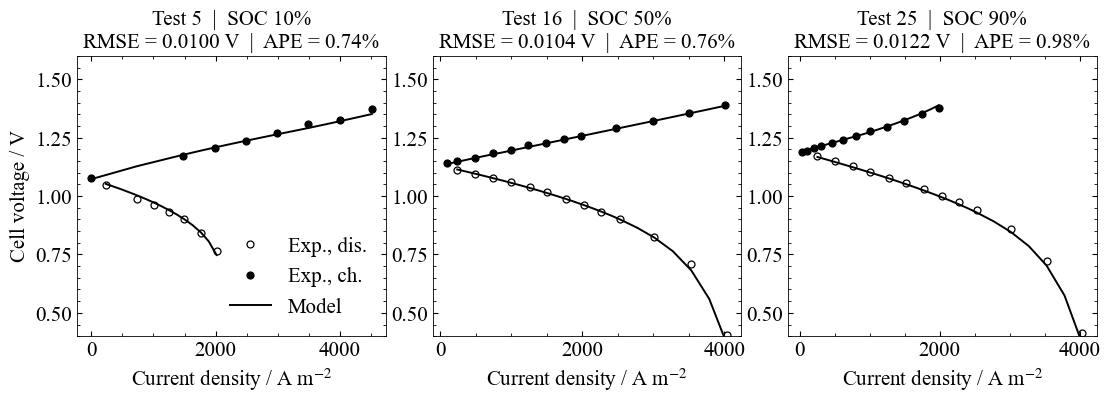

Saved -> <repo>\figures\E_cell_global.pdf

Per-test RMSE / APE:
  Test 5: RMSE = 0.0100 V  APE = 0.74%
  Test 16: RMSE = 0.0104 V  APE = 0.76%
  Test 25: RMSE = 0.0122 V  APE = 0.98%


In [5]:
plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman', 'Times', 'DejaVu Serif'],
    'mathtext.fontset': 'stix',
    'font.size': 15,
    'axes.labelsize': 15,
    'axes.titlesize': 15,
    'xtick.labelsize': 15,
    'ytick.labelsize': 15,
    'legend.fontsize': 15,
    'axes.linewidth': 0.6,
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'xtick.top': True,
    'ytick.right': True,
    'lines.linewidth': 1.2,
    'savefig.dpi': 600,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
})

fig, axes = plt.subplots(1, 3, figsize=(11, 4), sharey=False)

for ax, t in zip(axes, TEST_NOS):
    cfg = test_configs[t]
    r   = sim_results[t]

    # Experimental
    ax.plot(cfg["j_discharge"], cfg["E_exp_dis"],
            'o', ms=5, mfc='none', mec='k', mew=0.9, label='Exp., dis.')
    ax.plot(cfg["j_charge"],    cfg["E_exp_ch"],
            'o', ms=5, mfc='k',    mec='k', mew=0.9, label='Exp., ch.')

    # Model
    ax.plot(r["j_model_ch"],  r["E_model_ch"],  '-', color='k', lw=1.4, label='Model')
    ax.plot(r["j_model_dis"], r["E_model_dis"], '-', color='k', lw=1.4)

    ax.set_ylim(0.4, 1.6)
    ax.set_xlabel(r'Current density / A m$^{-2}$')
    ax.set_title(
        f"Test {t}  |  SOC {cfg['soc']:.0%}\n"
        f"RMSE = {r['mse']**0.5:.4f} V  |  APE = {r['ape']:.2f}%"
    )
    ax.xaxis.set_minor_locator(ticker.AutoMinorLocator())
    ax.yaxis.set_minor_locator(ticker.AutoMinorLocator())

axes[0].set_ylabel('Cell voltage / V')
axes[0].legend(frameon=False)

fig.tight_layout(pad=0.4)
out_path = ROOT / "figures" / "E_cell_global.pdf"
out_path.parent.mkdir(parents=True, exist_ok=True)
#fig.savefig(out_path, bbox_inches='tight')
plt.show()
print(f"Saved -> {out_path}")

# -- per-test MSE/APE summary --------------------------------------------------
print("\nPer-test RMSE / APE:")
for t in TEST_NOS:
    r = sim_results[t]
    print(f"  Test {t}: RMSE = {r['mse']**0.5:.4f} V  APE = {r['ape']:.2f}%")

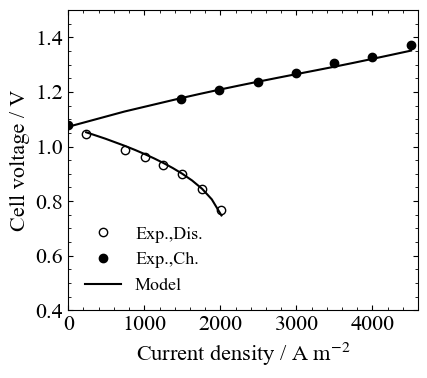

Saved -> <repo>\figures\E_cell_test5.pdf


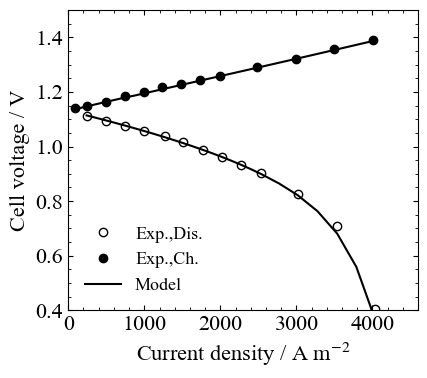

Saved -> <repo>\figures\E_cell_test16.pdf


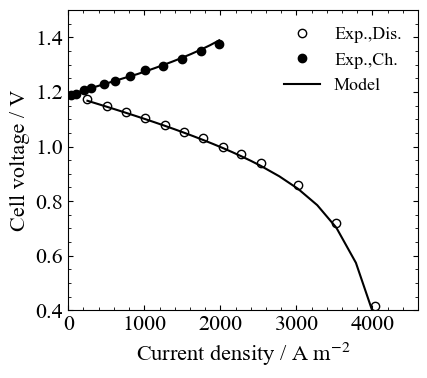

Saved -> <repo>\figures\E_cell_test25.pdf

Per-test RMSE / APE:
  Test 5: RMSE = 0.0100 V  APE = 0.74%
  Test 16: RMSE = 0.0104 V  APE = 0.76%
  Test 25: RMSE = 0.0122 V  APE = 0.98%


In [6]:
plt.rcParams.update({
    'font.family':       'serif',
    'font.serif':        ['Times New Roman', 'Times', 'DejaVu Serif'],
    'mathtext.fontset':  'stix',
    'font.size':         14,
    'axes.labelsize':    16,
    'axes.titlesize':    16,
    'xtick.labelsize':   16,
    'ytick.labelsize':   16,
    'legend.fontsize':   13,
    'axes.linewidth':    0.8,
    'xtick.direction':   'in',
    'ytick.direction':   'in',
    'xtick.top':         True,
    'ytick.right':       True,
    'lines.linewidth':   1.5,
    'savefig.dpi':       600,
    'pdf.fonttype':      42,
    'ps.fonttype':       42,
})

for t in TEST_NOS:
    cfg = test_configs[t]
    r   = sim_results[t]

    fig, ax = plt.subplots(figsize=(4.5, 4))

    # Experimental: open circles (discharge), filled circles (charge)
    ax.plot(cfg["j_discharge"], cfg["E_exp_dis"],
            'o', ms=6, mfc='none', mec='k', mew=1.0, label='Exp.,Dis.')
    ax.plot(cfg["j_charge"],    cfg["E_exp_ch"],
            'o', ms=6, mfc='k',    mec='k', mew=1.0, label='Exp.,Ch.')

    # Model
    ax.plot(r["j_model_ch"],  r["E_model_ch"],  '-', color='k', lw=1.5, label='Model')
    ax.plot(r["j_model_dis"], r["E_model_dis"], '-', color='k', lw=1.5)

    ax.set_ylim(0.4, 1.5)
    ax.set_xlim(0,4600)
    ax.set_xlabel(r'Current density / A m$^{-2}$')
    ax.set_ylabel('Cell voltage / V')
    ax.legend(frameon=False)
    ax.xaxis.set_minor_locator(ticker.AutoMinorLocator())
    ax.yaxis.set_minor_locator(ticker.AutoMinorLocator())
    ax.tick_params(which='both', direction='in', top=True, right=True)

    plt.tight_layout()
    out_path = ROOT / f"figures/E_cell_test{t}.pdf"
    out_path.parent.mkdir(parents=True, exist_ok=True)
    plt.savefig(out_path, bbox_inches='tight')
    plt.show()
    print(f"Saved -> {out_path}")

# -- per-test MSE/APE summary --------------------------------------------------
print("\nPer-test RMSE / APE:")
for t in TEST_NOS:
    r = sim_results[t]
    print(f"  Test {t}: RMSE = {r['mse']**0.5:.4f} V  APE = {r['ape']:.2f}%")